# Analisis Sentimen Publik terhadap Erupsi Gunung Berapi Indonesia (2021–2025)

> **NLP berbasis NER + Sentimen** | Sumber: Komentar YouTube | Python 3.11
>
> Kontributor: Aldani (data preparation) · Sahril (NER/first analysis) · Pankop/Naufal (sentiment/second analysis) · Azhar (evaluation)

In [1]:
import json
import csv
from pathlib import Path
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import numpy as np
from wordcloud import WordCloud

plt.rcParams.update({
    'figure.dpi': 120,
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
})
COLORS = ['#E05C5C', '#5B8DB8', '#6DBF67']   # negatif, netral, positif
ROOT = Path('..') if Path('../data').exists() else Path('.')


---
## 1. Project Overview

### Tujuan
Memahami bagaimana publik Indonesia merespons peristiwa erupsi gunung berapi melalui komentar di YouTube (2021–2025), menggunakan:

1. **Named Entity Recognition (NER)** — ekstraksi entitas (gunung, lokasi, bahaya, waktu, pemerintah, aktor sosial) dengan fine-tuning IndoBERT.
2. **Analisis Sentimen** — pelabelan per komentar (negatif / netral / positif) menggunakan pipeline berbasis leksikon domain.

### Pipeline
```
YouTube Scrape → Cleaning → Cleansing → Pre-Annotation → Human Annotation
      → BIO Alignment → IndoBERT Fine-Tuning → NER Eval
      → Sentiment Labeling (rules_v1) → Sentiment Eval
```

In [2]:
# Dataset overview table
overview = [
    ('Video sumber', '335', 'data/source/'),
    ('Komentar mentah (raw)', '87,840', 'data/raw/'),
    ('Setelah cleaning', '80,239', 'data/cleaning/'),
    ('Setelah cleansing', '79,524', 'data/cleansing/'),
    ('Spam judol dihapus', '50', 'data/cleansing/judol_comments_detected.csv'),
    ('Korpus NER (3-kolom)', '64,836', 'data/ner_distribution/data_text.csv'),
    ('Teranotasi manual (NER)', '18,537 (~28.6%)', 'data/ner_distribution/annotated/'),
    ('Train / Val / Test (tokenized)', '55,101 / 3,054 / 6,681', 'data/ner_distribution/data_distribution/'),
    ('Berlabel sentimen', '64,836', 'data/sentiment/labeled/'),
]
df_ov = pd.DataFrame(overview, columns=['Tahap', 'Jumlah', 'File'])
df_ov.style.set_caption('Ringkasan Dataset').hide(axis='index')

Tahap,Jumlah,File
Video sumber,335,data/source/
Komentar mentah (raw),"87,840",data/raw/
Setelah cleaning,"80,239",data/cleaning/
Setelah cleansing,"79,524",data/cleansing/
Spam judol dihapus,50,data/cleansing/judol_comments_detected.csv
Korpus NER (3-kolom),"64,836",data/ner_distribution/data_text.csv
Teranotasi manual (NER),"18,537 (~28.6%)",data/ner_distribution/annotated/
Train / Val / Test (tokenized),"55,101 / 3,054 / 6,681",data/ner_distribution/data_distribution/
Berlabel sentimen,"64,836",data/sentiment/labeled/


---
## 2. Pipeline Data

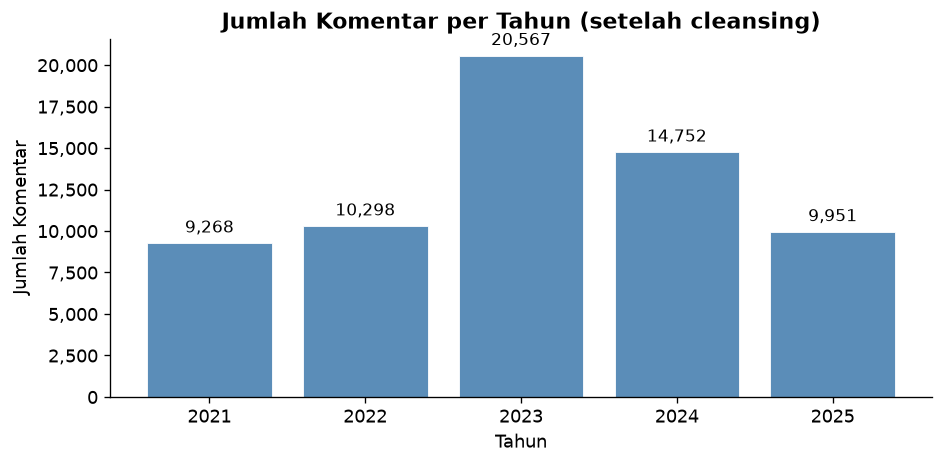

In [3]:
# Comments by year — bar chart
year_counts = {'2021': 9268, '2022': 10298, '2023': 20567, '2024': 14752, '2025': 9951}

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(year_counts.keys(), year_counts.values(), color='#5B8DB8', edgecolor='white', linewidth=0.5)
ax.bar_label(bars, fmt='{:,.0f}', padding=4, fontsize=10)
ax.set_title('Jumlah Komentar per Tahun (setelah cleansing)', fontsize=13, fontweight='bold')
ax.set_xlabel('Tahun')
ax.set_ylabel('Jumlah Komentar')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.show()

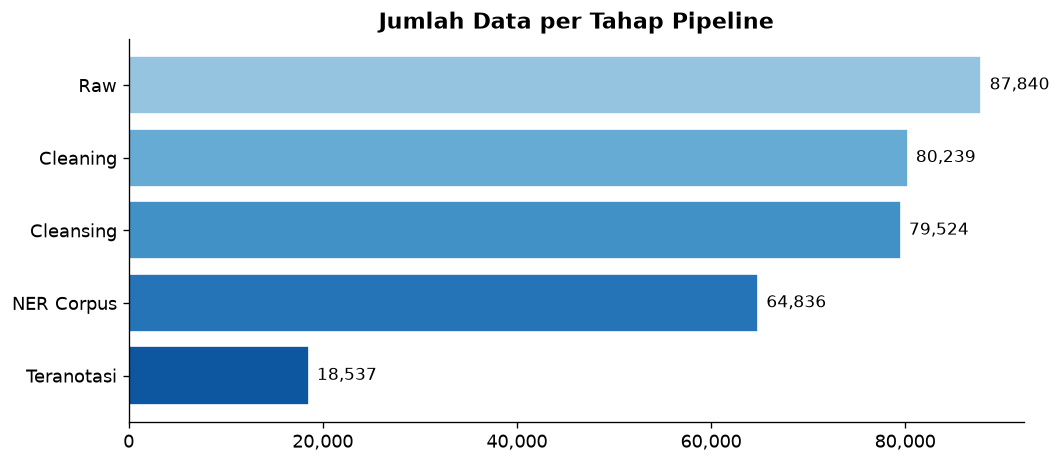

In [4]:
# Funnel chart: row count at each stage
stages = [
    ('Raw', 87840),
    ('Cleaning', 80239),
    ('Cleansing', 79524),
    ('NER Corpus', 64836),
    ('Teranotasi', 18537),
]
labels, vals = zip(*stages)

fig, ax = plt.subplots(figsize=(9, 4))
colors = plt.cm.Blues(np.linspace(0.4, 0.85, len(vals)))
bars = ax.barh(labels[::-1], vals[::-1], color=colors[::-1], edgecolor='white')
ax.bar_label(bars, fmt='{:,.0f}', padding=5, fontsize=10)
ax.set_title('Jumlah Data per Tahap Pipeline', fontsize=13, fontweight='bold')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout()
plt.show()

---
## 3. Eksplorasi Korpus

In [5]:
# Load cleansed data
df_cleansed = pd.read_csv(ROOT / 'data/cleansing/youtube_comments_cleansed.csv')
print(f'Shape: {df_cleansed.shape}')
df_cleansed[['video_year', 'text_cleansed']].head(3)

Shape: (64836, 14)


,video_year,text_cleansed
0,2021,sekarang 2025 meletus lagi
1,2021,bencana semoga segera berakhir
2,2021,semoga warga disekitar gunung merapi terselama...


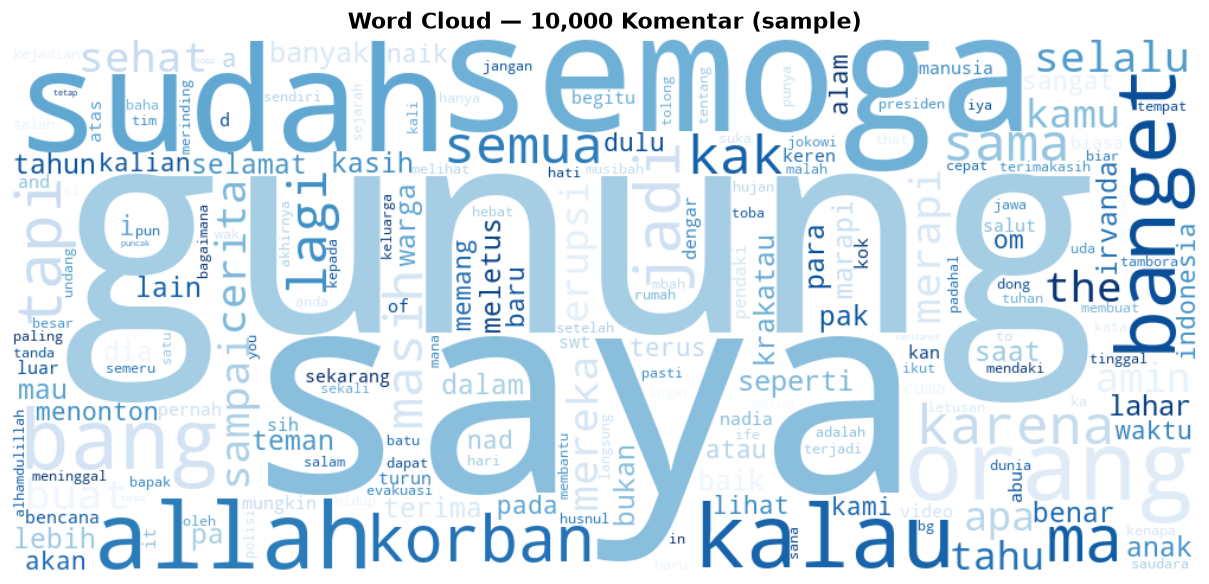

In [6]:
# Word cloud dari seluruh komentar (sample 10k untuk kecepatan)
sample_text = ' '.join(df_cleansed['text_cleansed'].dropna().sample(10000, random_state=42))

wc = WordCloud(
    width=1000, height=450, background_color='white',
    colormap='Blues', max_words=200, collocations=False,
    stopwords={'yang', 'di', 'dan', 'ke', 'ini', 'itu', 'dengan', 'untuk',
               'ada', 'tidak', 'ya', 'aja', 'juga', 'bisa', 'dari', 'kita',
               'saja', 'nih', 'nya', 'ku', 'mu', 'lah', 'tuh'},
).generate(sample_text)

fig, ax = plt.subplots(figsize=(12, 5))
ax.imshow(wc, interpolation='bilinear')
ax.axis('off')
ax.set_title('Word Cloud — 10,000 Komentar (sample)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

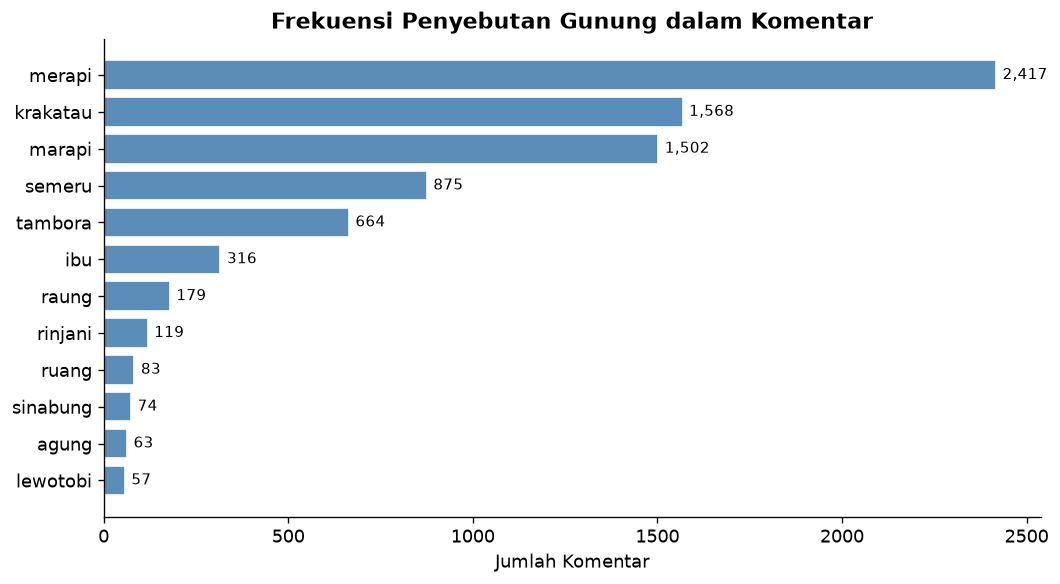

In [7]:
# Top volcanoes mentioned (from video titles as proxy)
volcanoes = [
    'semeru', 'merapi', 'marapi', 'krakatau', 'lewotobi',
    'ruang', 'ibu', 'sinabung', 'raung', 'agung', 'bromo',
    'ijen', 'rinjani', 'kerinci', 'tambora',
]
text_lower = df_cleansed['text_cleansed'].str.lower().fillna('')
vol_counts = {v: text_lower.str.contains(r'\b' + v + r'\b').sum() for v in volcanoes}
vol_counts = dict(sorted(vol_counts.items(), key=lambda x: -x[1])[:12])

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(list(vol_counts.keys())[::-1], list(vol_counts.values())[::-1],
               color='#5B8DB8', edgecolor='white')
ax.bar_label(bars, fmt='{:,.0f}', padding=4, fontsize=9)
ax.set_title('Frekuensi Penyebutan Gunung dalam Komentar', fontsize=13, fontweight='bold')
ax.set_xlabel('Jumlah Komentar')
plt.tight_layout()
plt.show()

---
## 4. Proses Anotasi NER

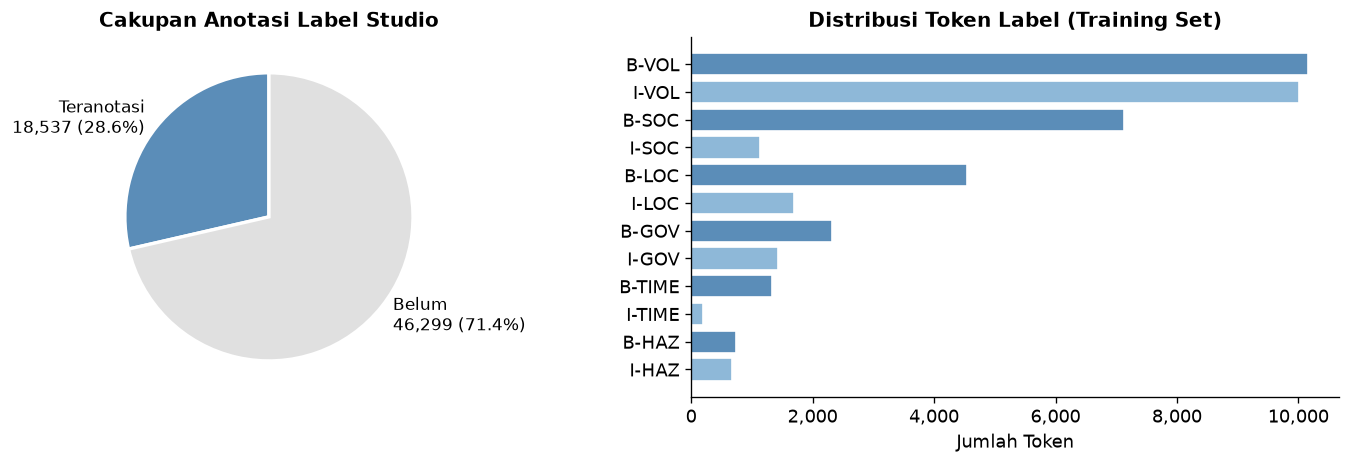

In [8]:
# Annotation coverage
total_tasks = 64836
annotated = 18537
unannotated = total_tasks - annotated

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Pie: coverage
axes[0].pie(
    [annotated, unannotated],
    labels=[f'Teranotasi\n{annotated:,} (28.6%)', f'Belum\n{unannotated:,} (71.4%)'],
    colors=['#5B8DB8', '#E0E0E0'], startangle=90,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2},
    textprops={'fontsize': 10},
)
axes[0].set_title('Cakupan Anotasi Label Studio', fontsize=12, fontweight='bold')

# Bar: token label distribution (training set)
token_labels = {
    'B-VOL': 10159, 'I-VOL': 10006,
    'B-SOC': 7131,  'I-SOC': 1138,
    'B-LOC': 4543,  'I-LOC': 1699,
    'B-GOV': 2325,  'I-GOV': 1433,
    'B-TIME': 1335, 'I-TIME': 188,
    'B-HAZ': 731,   'I-HAZ': 680,
}
tok_colors = ['#5B8DB8' if k.startswith('B-') else '#8EB8D8' for k in token_labels]
axes[1].barh(list(token_labels.keys())[::-1], list(token_labels.values())[::-1],
             color=tok_colors[::-1], edgecolor='white')
axes[1].set_title('Distribusi Token Label (Training Set)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Jumlah Token')
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

plt.tight_layout()
plt.show()

### Skema Entitas (13 Label BIO)

| Kode | Nama | Contoh |
|------|------|--------|
| `VOL` | Gunung Berapi | gunung semeru, merapi, krakatau |
| `LOC` | Lokasi | lumajang, yogyakarta, halmahera |
| `HAZ` | Bahaya | awan panas, lahar hujan, debu vulkanik |
| `TIME` | Waktu | 7 desember 2021, dini hari |
| `GOV` | Pemerintah | PVMBG, BNPB, Basarnas, TNI |
| `SOC` | Aktor Sosial | pendaki, pengungsi, relawan, netizen |

---
## 5. Model NER — IndoBERT

### Arsitektur & Konfigurasi Training

| Parameter | Nilai |
|-----------|-------|
| Base model | `indobenchmark/indobert-base-p1` |
| Task | Token Classification (NER) |
| Jumlah label | 13 (BIO × 6 entitas + O) |
| Epochs | 5 |
| Learning rate | 3e-5 |
| Batch size (train) | 16 |
| Weight decay | 0.01 |
| Warmup steps | 50 |
| Mixed precision | FP16 (Colab GPU) |
| Best model metric | F1 (seqeval) |
| Platform | Google Colab |

### Split Dataset

| Split | Records | Token count (approx) |
|-------|---------|----------------------|
| Train | 55,101 | ~984,000 |
| Val | 3,054 | ~54,000 |
| Test | 6,681 | ~119,000 |

---
## 6. Evaluasi NER (Test Set)

In [9]:
# Load test set eval results
eval_path = ROOT / 'evaluation' / 'ner_eval_results.json'

with open(eval_path) as f:
    ner_eval = json.load(f)

print(f"Test records : {ner_eval['test_rows']:,}")
print(f"Inference time: {ner_eval['inference_seconds']}s")
micro = ner_eval['micro_avg']
print(f"\nMicro Avg  P={micro['precision']:.4f}  R={micro['recall']:.4f}  F1={micro['f1']:.4f}")

Test records : 6,681
Inference time: 92.2s

Micro Avg  P=0.9747  R=0.9818  F1=0.9783


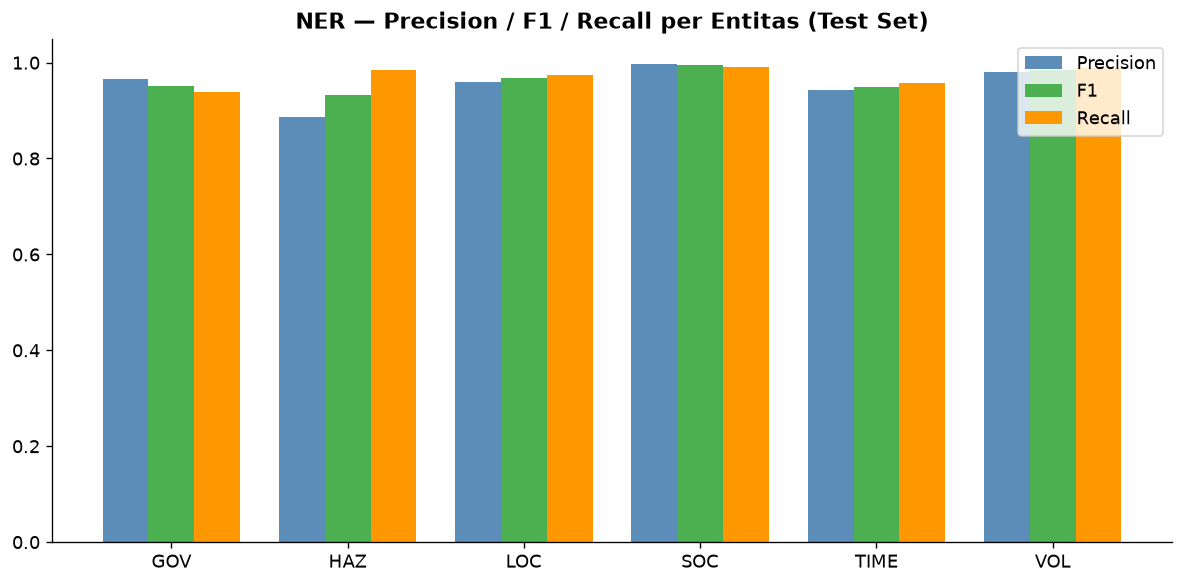

In [10]:
# Per-entity bar chart
per_ent = ner_eval['per_entity']
entities = [e for e in per_ent if e not in ('micro avg', 'macro avg', 'weighted avg')]
f1s = [per_ent[e]['f1-score'] for e in entities]
precs = [per_ent[e]['precision'] for e in entities]
recs = [per_ent[e]['recall'] for e in entities]

x = np.arange(len(entities))
w = 0.26
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - w, precs, w, label='Precision', color='#5B8DB8')
ax.bar(x,     f1s,   w, label='F1',        color='#4CAF50')
ax.bar(x + w, recs,  w, label='Recall',    color='#FF9800')
ax.set_xticks(x)
ax.set_xticklabels(entities, fontsize=11)
ax.set_ylim(0, 1.05)
ax.set_title('NER — Precision / F1 / Recall per Entitas (Test Set)', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

In [11]:
# Summary table
rows = []
for e in entities:
    m = per_ent[e]
    rows.append({
        'Entitas': e,
        'Precision': f"{m['precision']:.4f}",
        'Recall': f"{m['recall']:.4f}",
        'F1': f"{m['f1-score']:.4f}",
        'Support': int(m['support']),
    })
# add micro avg
rows.append({
    'Entitas': 'micro avg',
    'Precision': f"{micro['precision']:.4f}",
    'Recall': f"{micro['recall']:.4f}",
    'F1': f"{micro['f1']:.4f}",
    'Support': '',
})
pd.DataFrame(rows).style.hide(axis='index')

Entitas,Precision,Recall,F1,Support
GOV,0.9648,0.9384,0.9514,146
HAZ,0.8873,0.9844,0.9333,64
LOC,0.9600,0.9746,0.9673,394
SOC,0.9966,0.9916,0.9941,594
TIME,0.9421,0.9580,0.9500,119
VOL,0.9798,0.9887,0.9842,884
micro avg,0.9747,0.9818,0.9783,


### Validasi (dari Colab — referensi)

| Entitas | Precision | Recall | F1 |
|---------|-----------|--------|---------|
| VOL | 0.9972 | 0.9972 | 0.9972 |
| SOC | 1.0000 | 0.9963 | 0.9981 |
| LOC | 0.9963 | 0.9854 | 0.9908 |
| GOV | 0.9659 | 0.9551 | 0.9605 |
| TIME | 0.9583 | 0.9583 | 0.9583 |
| HAZ | 0.8750 | 0.9333 | 0.9032 |
| **micro avg** | **0.9903** | **0.9875** | **0.9889** |

---
### 6.1 Visualisasi Graph Entitas (Knowledge Graph Prototype)
Analisis keterhubungan antar entitas: bagaimana Gunung (), Lokasi (), Bahaya (), Pemerintah (), dan Aktor Sosial () saling terhubung dalam percakapan publik.


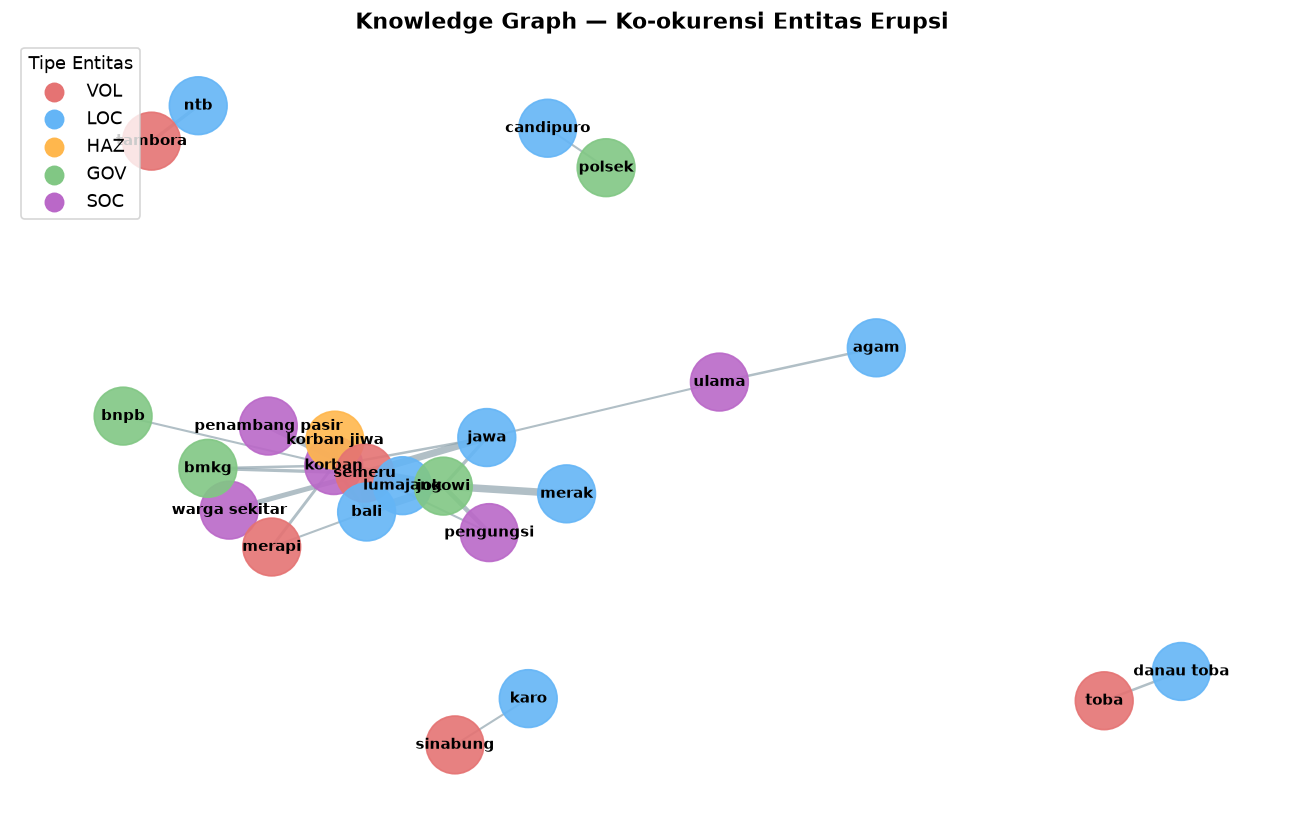

In [12]:
import itertools
import networkx as nx
from collections import Counter

# Ekstraksi ko-okurensi entitas dari data teranotasi
annotated_path = ROOT / "data/ner_distribution/annotated/annotated.json"
with open(annotated_path, encoding="utf-8") as f:
    ann_data = json.load(f)

edges = Counter()
node_type = {}
ENTITY_MAP = {"VOLCANO": "VOL", "LOCATION": "LOC", "HAZARD": "HAZ", "GOVERNMENT": "GOV", "SOCIAL ACTORS": "SOC"}

for item in ann_data[:10000]:
    anns = item.get("annotations", [])
    if not anns or not anns[0].get("result"):
        continue
    ents = set()
    for r in anns[0]["result"]:
        lbl = r["value"]["labels"][0]
        txt = r["value"]["text"].strip().lower()
        if txt.startswith("gunung "):
            txt = txt.replace("gunung ", "")
        if len(txt) > 2 and lbl in ENTITY_MAP:
            short_lbl = ENTITY_MAP[lbl]
            ents.add((short_lbl, txt))
            node_type[txt] = short_lbl
    for (l1, e1), (l2, e2) in itertools.combinations(ents, 2):
        if l1 != l2:
            pair = tuple(sorted([e1, e2]))
            edges[pair] += 1

# Bangun graph dari 30 relasi terkuat
G = nx.Graph()
for (u, v), w in edges.most_common(30):
    G.add_edge(u, v, weight=w)

TYPE_COLORS = {"VOL": "#E57373", "LOC": "#64B5F6", "HAZ": "#FFB74D", "GOV": "#81C784", "SOC": "#BA68C8"}
node_colors = [TYPE_COLORS.get(node_type.get(n, ""), "#B0BEC5") for n in G.nodes()]
edge_widths = [max(1.0, min(5.0, G[u][v]["weight"] / 4.0)) for u, v in G.edges()]

plt.figure(figsize=(11, 7))
pos = nx.spring_layout(G, k=0.55, seed=42)
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=1200, alpha=0.9)
nx.draw_networkx_edges(G, pos, width=edge_widths, edge_color="#90A4AE", alpha=0.7)
nx.draw_networkx_labels(G, pos, font_size=9, font_weight="bold")

# Legend
for typ, col in TYPE_COLORS.items():
    plt.scatter([], [], color=col, label=typ, s=120)
plt.legend(title="Tipe Entitas", loc="upper left", frameon=True)
plt.title("Knowledge Graph — Ko-okurensi Entitas Erupsi", fontsize=13, fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.show()


---
## 7. Analisis Sentimen

In [13]:
# Load sentiment labels
df_sent = pd.read_csv(ROOT / 'data/sentiment/labeled/sentiment_labels_rules.csv')
print(f'Shape: {df_sent.shape}')
print(df_sent['label_name'].value_counts())

Shape: (64836, 14)
label_name
netral     37567
positif    20210
negatif     7059
Name: count, dtype: int64


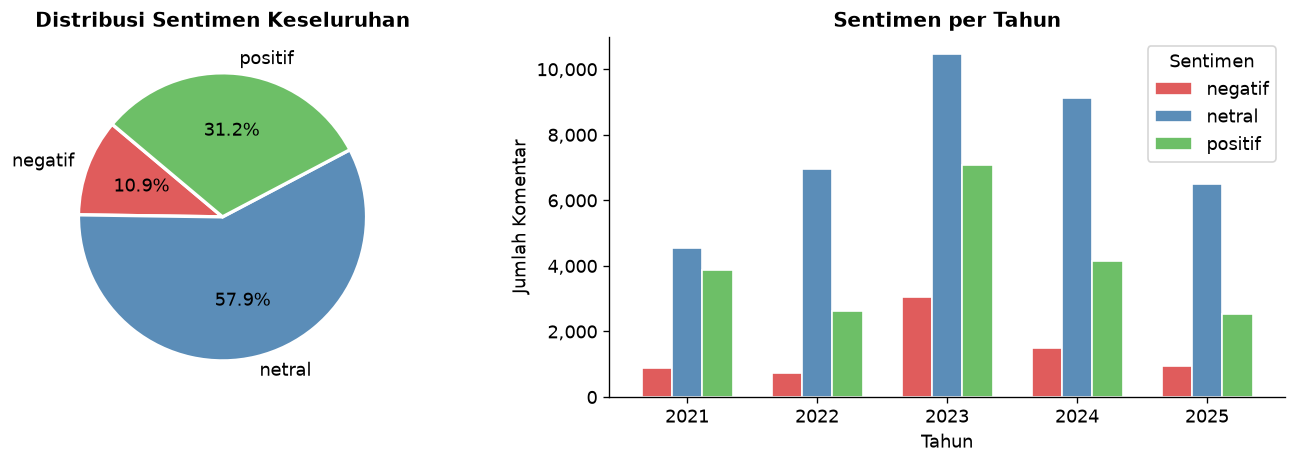

In [14]:
# Overall sentiment distribution — pie
sent_counts = df_sent['label_name'].value_counts()
label_order = ['negatif', 'netral', 'positif']
vals_sent = [sent_counts[l] for l in label_order]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

wedges, texts, autotexts = axes[0].pie(
    vals_sent, labels=label_order,
    autopct='%1.1f%%', colors=COLORS,
    startangle=140,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2},
)
axes[0].set_title('Distribusi Sentimen Keseluruhan', fontsize=12, fontweight='bold')

# Bar: by year
year_sent = df_sent.groupby(['video_year', 'label_name']).size().unstack(fill_value=0)
year_sent = year_sent[label_order]
year_sent.plot(kind='bar', ax=axes[1], color=COLORS, edgecolor='white', width=0.7)
axes[1].set_title('Sentimen per Tahun', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Tahun')
axes[1].set_ylabel('Jumlah Komentar')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Sentimen')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

plt.tight_layout()
plt.show()

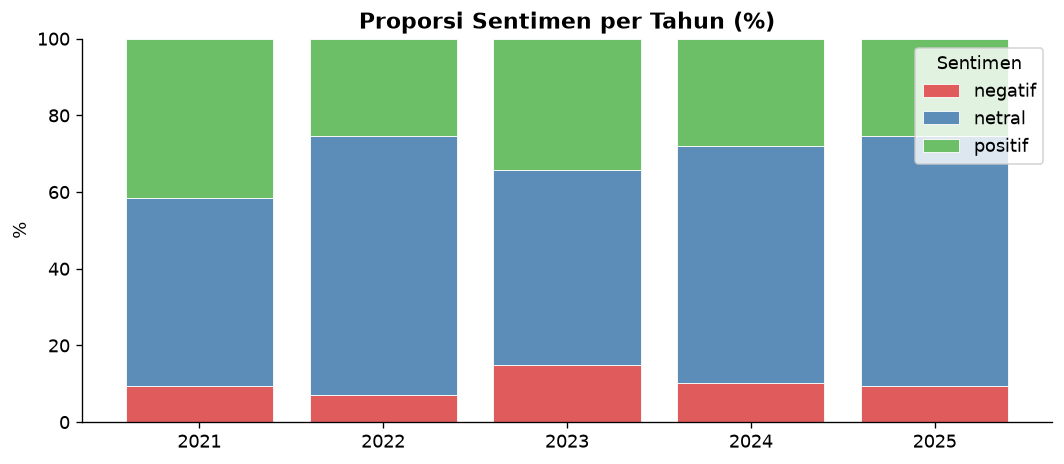

In [15]:
# Sentiment proportion by year (stacked 100%)
year_prop = year_sent.div(year_sent.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(9, 4))
bottom = np.zeros(len(year_prop))
for col, color in zip(label_order, COLORS):
    ax.bar(year_prop.index.astype(str), year_prop[col], bottom=bottom,
           label=col, color=color, edgecolor='white', linewidth=0.5)
    bottom += year_prop[col].values
ax.set_title('Proporsi Sentimen per Tahun (%)', fontsize=13, fontweight='bold')
ax.set_ylabel('%')
ax.set_ylim(0, 100)
ax.legend(title='Sentimen', loc='upper right')
plt.tight_layout()
plt.show()

In [16]:
# Accuracy of rules_v1 (from gold eval)
gold_path = ROOT / 'data/sentiment/gold/eval_rules.json'
with open(gold_path) as f:
    gold_eval = json.load(f)

print('=== Evaluasi rules_v1 ===')
for dataset, result in gold_eval.items():
    print(f"\n{dataset}")
    print(f"  Rows     : {result['rows']}")
    print(f"  Accuracy : {result['accuracy']:.4f}")
    print(f"  Macro F1 : {result['classification_report']['macro avg']['f1-score']:.4f}")

=== Evaluasi rules_v1 ===

gold_sample.csv
  Rows     : 120
  Accuracy : 0.8417
  Macro F1 : 0.8425

gold_sample_holdout.csv
  Rows     : 120
  Accuracy : 0.8500
  Macro F1 : 0.8369


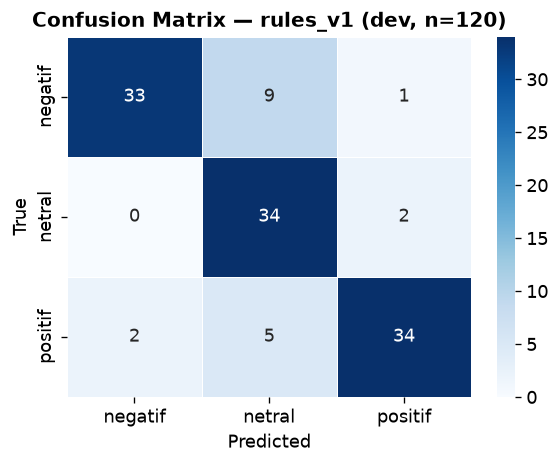

In [17]:
# Confusion matrix — gold_sample (dev)
cm_data = gold_eval['gold_sample.csv']['confusion_matrix']
labels_cm = gold_eval['gold_sample.csv']['labels']

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm_data, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels_cm, yticklabels=labels_cm, ax=ax,
            linewidths=0.5, linecolor='white')
ax.set_title('Confusion Matrix — rules_v1 (dev, n=120)', fontsize=12, fontweight='bold')
ax.set_ylabel('True')
ax.set_xlabel('Predicted')
plt.tight_layout()
plt.show()

In [18]:
# Sentiment examples per class
print('=== Contoh Komentar per Sentimen ===\n')
for label in ['negatif', 'netral', 'positif']:
    examples = (
        df_sent[df_sent['label_name'] == label]['text']
        .dropna()
        .sample(3, random_state=42)
        .tolist()
    )
    print(f'[{label.upper()}]')
    for ex in examples:
        print(f'  • {ex}')
    print()

=== Contoh Komentar per Sentimen ===

[NEGATIF]
  • awal berita ini rame saya sempet mau bilang keramat jilid 2 nih begitu eh ternyata marapi plot twist keramat itu film yang diambil dari kisah nyata kelompok orang yang rencana mau membuat film pas di lokasi ada kejadian di luar nurul yang menyebabkan kru tersebut hilang di dunia lain nah pas ilangnya tuh bawa handycam seperti begitu jadi ada dokumentasinya dan itu ngeri asli kalau mau menonton bisa googling saja tapi yang ada itu video buatan yang asli disimpen dimana begitu saya lupa tapi masih di simpen kok
  • hore mampus sok melawan alam bayar tuh pake nyawa ampas sampah memang buang2 duit saja ampas2 sampah najis
  • terharu kali sampai nangis ter the best lah wawak saya ni

[NETRAL]
  • pendaki gunung sejati
  • suaranya cerita sampai gemetar tahan tangissnyaa
  • iya kak 3 orang arbi sama ridho di bekas warung ada di podcast bg dika bilang malam itu menemukan orang minta tolong dalam tenda warna merah pas dicek ada 1 orang cowo

---
## 8. Kesimpulan

### Temuan Utama

1. **Dataset** — 64,836 komentar YouTube dari 335 video erupsi gunung (2021–2025), melewati 4 tahap prapemrosesan.
2. **NER IndoBERT** — Fine-tuning `indobert-base-p1` pada 18,537 anotasi manual menghasilkan F1 ~0.98 (micro) pada test set, dengan entitas VOL dan SOC mencapai F1 tertinggi.
3. **Sentimen** — Pipeline rules_v1 berbasis leksikon domain mencapai akurasi 84.2–85.0% pada gold sample. Distribusi: 10.9% negatif, 57.9% netral, 31.2% positif.
4. **Tren temporal** — Lonjakan komentar signifikan pada 2023, bersamaan dengan banyak kejadian erupsi (Marapi, Ruang, Ibu, Lewotobi). Proporsi sentimen negatif juga tertinggi di 2023.

### Keterbatasan

- Hanya ~28.6% korpus dianotasi secara manual untuk NER — kualitas bergantung pada pre-annotation otomatis.
- Sentiment rules_v1 masih rule-based; 34,800 komentar (53.7%) memiliki confidence rendah dan butuh review manual.
- Data YouTube bias ke konten yang mendapat banyak views; komentar di video kecil tidak terwakili.

### Potensi Pengembangan

- Fine-tuning model sentimen berbasis IndoBERT (menggantikan rules_v1).
- Analisis sentimen per entitas (VOL, GOV, SOC) — bukan hanya per komentar.
- Ekspansi ke platform lain (Twitter/X, TikTok) untuk triangulasi opini publik.